# Análise exploratória — exportações brasileiras

Exploração da fato mensal por seção carregada no PostgreSQL. As conclusões são descritivas; FOB/kg é uma razão agregada, não um preço unitário.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psycopg
from dotenv import load_dotenv

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
load_dotenv(PROJECT_ROOT / '.env')
dsn = os.environ['PG_DSN']

In [2]:
query = '''
SELECT t.data_calendario, t.ano, t.numero_mes, s.codigo_secao, s.nome_secao,
       f.valor_fob_usd, f.quilograma_liquido
FROM fato_exportacao_mensal f
JOIN dim_tempo t USING (tempo_id)
JOIN dim_secao_produto s USING (secao_id)
ORDER BY t.data_calendario, s.codigo_secao
'''
with psycopg.connect(dsn) as connection:
    with connection.cursor() as cursor:
        cursor.execute(query)
        columns = [description.name for description in cursor.description]
        df = pd.DataFrame(cursor.fetchall(), columns=columns)

df['data_calendario'] = pd.to_datetime(df['data_calendario'])
df['valor_fob_usd'] = df['valor_fob_usd'].astype('float64')
df['quilograma_liquido'] = df['quilograma_liquido'].astype('float64')
df.head(), df.shape

(  data_calendario   ano  numero_mes codigo_secao  \
 0      2022-01-01  2022           1            I   
 1      2022-01-01  2022           1           II   
 2      2022-01-01  2022           1          III   
 3      2022-01-01  2022           1           IV   
 4      2022-01-01  2022           1           IX   
 
                                           nome_secao  valor_fob_usd  \
 0           Animais vivos e produtos do reino animal   1.604083e+09   
 1                          Produtos do reino vegetal   2.976734e+09   
 2  Gorduras e óleos animais ou vegetais; Produtos...   2.743904e+08   
 3  Produtos das indútrias alimentares; Bebidas, l...   1.999586e+09   
 4  Madeira, carvão vegetal e obras de madeira; Co...   3.939304e+08   
 
    quilograma_liquido  
 0        5.882841e+08  
 1        6.222293e+09  
 2        2.042987e+08  
 3        3.385440e+09  
 4        8.759626e+08  ,
 (1008, 7))

In [3]:
profile = {
    'linhas': len(df),
    'meses': df['data_calendario'].dt.to_period('M').nunique(),
    'secoes': df['codigo_secao'].nunique(),
    'nulos': int(df.isna().sum().sum()),
    'chaves_duplicadas': int(df.duplicated(['data_calendario', 'codigo_secao']).sum()),
}
profile, df[['valor_fob_usd', 'quilograma_liquido']].describe(percentiles=[.01, .25, .5, .75, .99])

({'linhas': 1008,
  'meses': 48,
  'secoes': 21,
  'nulos': 0,
  'chaves_duplicadas': 0},
        valor_fob_usd  quilograma_liquido
 count   1.008000e+03        1.008000e+03
 mean    1.348369e+09        3.186792e+09
 std     2.026285e+09        9.182769e+09
 min     3.752188e+06        3.195000e+03
 1%      9.444709e+06        6.225080e+03
 25%     1.129524e+08        3.036511e+07
 50%     4.391772e+08        1.871886e+08
 75%     1.557676e+09        1.139812e+09
 99%     8.693721e+09        4.591247e+10
 max     9.395478e+09        5.266109e+10)

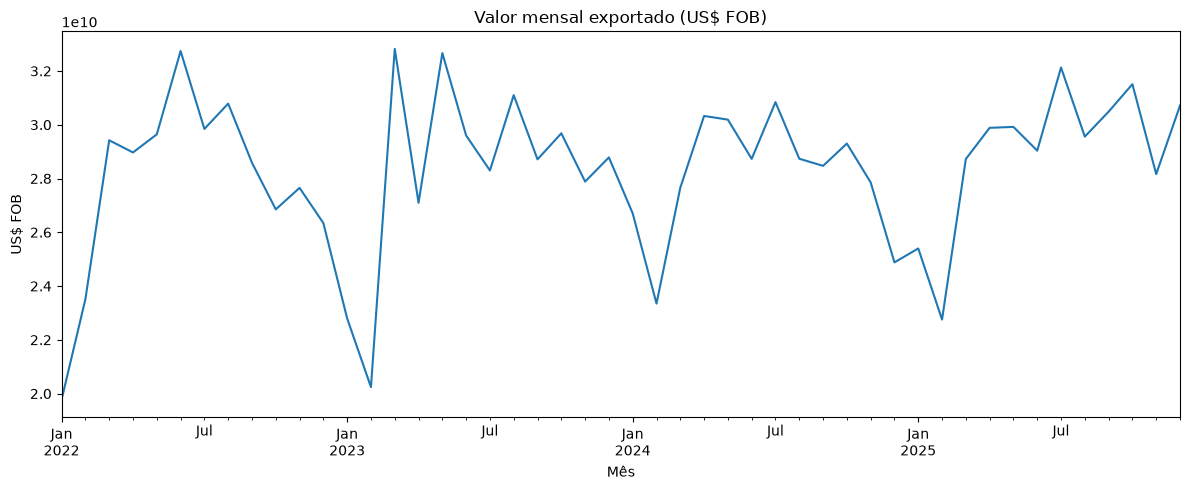

In [4]:
monthly_total = df.groupby(['data_calendario', 'ano', 'numero_mes'], as_index=False)['valor_fob_usd'].sum()
monthly_total = monthly_total[monthly_total['data_calendario'].dt.day == 1]
ax = monthly_total.plot(x='data_calendario', y='valor_fob_usd', figsize=(12, 5),
                        title='Valor mensal exportado (US$ FOB)', legend=False)
ax.set_xlabel('Mês')
ax.set_ylabel('US$ FOB')
plt.tight_layout()

In [5]:
annual = df.groupby(['ano', 'codigo_secao', 'nome_secao'], as_index=False)['valor_fob_usd'].sum()
annual['participacao_fob'] = annual['valor_fob_usd'] / annual.groupby('ano')['valor_fob_usd'].transform('sum')
annual_pivot = annual.pivot(index='nome_secao', columns='ano', values='participacao_fob').fillna(0)
annual_pivot['mudanca_2022_2025_pp'] = (annual_pivot[2025] - annual_pivot[2022]) * 100
annual_pivot.sort_values('mudanca_2022_2025_pp', ascending=False)

ano,2022,2023,2024,2025,mudanca_2022_2025_pp
nome_secao,,,,,
Animais vivos e produtos do reino animal,0.076805,0.070806,0.080462,0.093975,1.717008
Material de transporte,0.046468,0.049322,0.050461,0.058154,1.168537
"Produtos das indútrias alimentares; Bebidas, líquidos alcoólicos e vinagres; Tabaco e seus sucedâneos manufaturados",0.098693,0.116600,0.124262,0.104669,0.597540
"Máquinas e aparelhos, material elétrico e suas partes; Aparelhos de gravação ou reprodução de som, aparelhos de gravação ou reprodução de imagens e de som em televisão, e suas partes e acessórios",0.050100,0.054746,0.052764,0.054521,0.442073
"Pérolas naturais ou cultivadas, pedras preciosas ou semipreciosas e semelhantes, metais preciosos, metais folheados ou chapeados de metais preciosos, e suas obras; Bijuteria; Moedas",0.016871,0.012026,0.013217,0.020658,0.378726
Pastas de madeira ou de outras matérias fibrosas celulósicas; Papel ou cartão para reciclar (desperdícios e aparas); Papel e suas obras,0.033501,0.030659,0.039003,0.036386,0.288495
Matérias têxteis e suas obras,0.014465,0.011889,0.018033,0.016894,0.242839
"Instrumentos e aparelhos de ótica, fotografia ou cinematografia, medida, controle ou de precisão; Instrumentos e aparelhos médico-cirúrgicos; Relógios e aparelhos semelhantes; Instrumentos musicais; Suas partes e acessórios",0.002951,0.003457,0.003698,0.003721,0.076985
"Objetos de arte, de coleção e antiguidades",0.000619,0.000773,0.000831,0.000655,0.003635


## Interpretação

Use a tabela e os gráficos para identificar as seções com maior ganho/perda de participação. Investigue valores extremos consultando a série e o JSON bruto antes de classificá-los como erro; não os remova automaticamente. Complete a narrativa com os resultados efetivamente observados e compare as agregações com o dashboard.